# Task 2: Credit Risk Prediction

## Introduction
Credit risk prediction uses applicant information to estimate whether a loan applicant may default on a loan.

## Problem Statement
The objective is to build a classification model that predicts loan approval status using applicant information as a practical proxy.

## Objectives
- Load and explore the loan prediction dataset.
- Handle missing values.
- Visualize loan amount, education, and income.
- Train a classification model.
- Evaluate the model using accuracy and a confusion matrix.

## Tools and Libraries
- Python
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("train_u6lujuX_CVtuZ9i (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [5]:
df.describe(include="all")

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,614,601,611,599,614,582,614.000000,614.000000,592.000000,600.00000,564.000000,614,614
unique,614,2,2,4,2,2,NaN,NaN,NaN,NaN,NaN,3,2
top,LP001002,Male,Yes,0,Graduate,No,NaN,NaN,NaN,NaN,NaN,Semiurban,Y
freq,1,489,398,345,480,500,NaN,NaN,NaN,NaN,NaN,233,422
mean,NaN,NaN,NaN,NaN,NaN,NaN,5403.459283,1621.245798,146.412162,342.00000,0.842199,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,6109.041673,2926.248369,85.587325,65.12041,0.364878,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,150.000000,0.000000,9.000000,12.00000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2877.500000,0.000000,100.000000,360.00000,1.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,3812.500000,1188.500000,128.000000,360.00000,1.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,5795.000000,2297.250000,168.000000,360.00000,1.000000,NaN,NaN


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (614, 13)


In [9]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary

,Missing Count,Missing Percentage
Loan_ID,0,0.00
Gender,13,2.12
Married,3,0.49
Dependents,15,2.44
Education,0,0.00
Self_Employed,32,5.21
ApplicantIncome,0,0.00
CoapplicantIncome,0,0.00
LoanAmount,22,3.58
Loan_Amount_Term,14,2.28


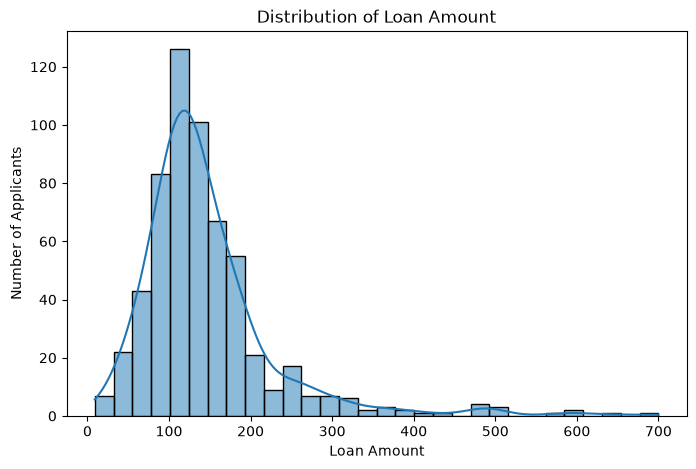

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="LoanAmount", bins=30, kde=True)

plt.title("Distribution of Loan Amount")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applicants")
plt.show()

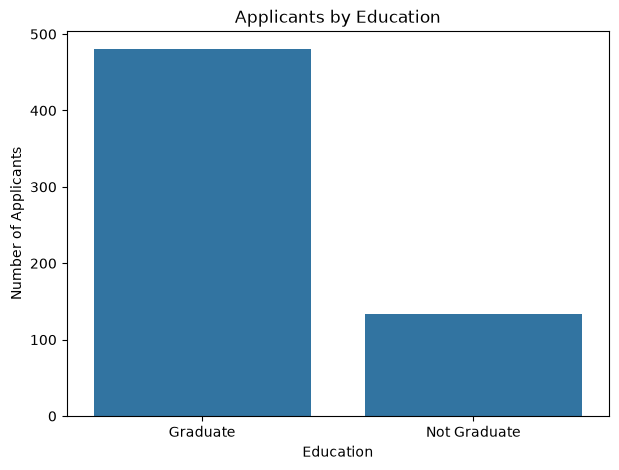

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Education")

plt.title("Applicants by Education")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.show()

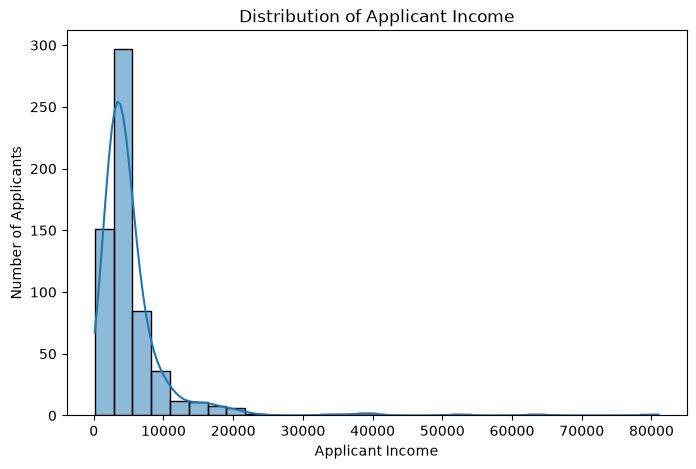

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="ApplicantIncome", bins=30, kde=True)

plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")
plt.show()

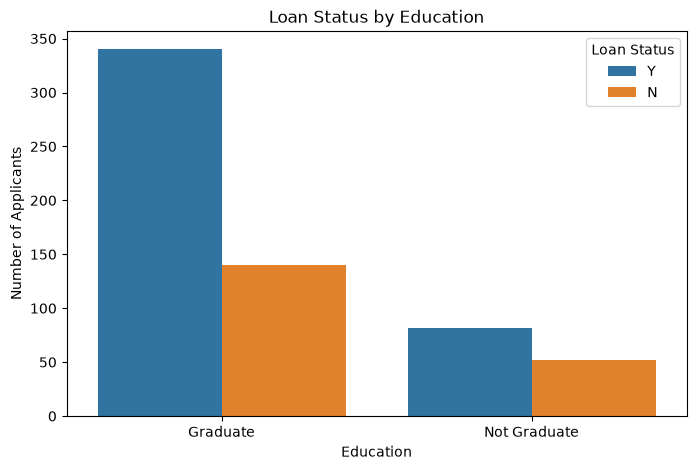

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Education", hue="Loan_Status")

plt.title("Loan Status by Education")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.legend(title="Loan Status")
plt.show()

In [14]:
df_model = df.dropna(subset=["Loan_Status"]).copy()

print("Rows available for modeling:", df_model.shape[0])
print("Loan status categories:", df_model["Loan_Status"].unique())

Rows available for modeling: 614
Loan status categories: <StringArray>
['Y', 'N']
Length: 2, dtype: str


In [15]:
X = df_model.drop(columns=["Loan_Status", "Loan_ID"], errors="ignore")

y = df_model["Loan_Status"].map({
    "N": 0,
    "Y": 1
})

valid_rows = y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (614, 11)
Target shape: (614,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 491
Testing rows: 123


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

In [18]:
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical columns:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


C:\Users\Malik\AppData\Local\Temp\ipykernel_19800\1903318766.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [19]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [20]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [21]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [22]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 86.18 %


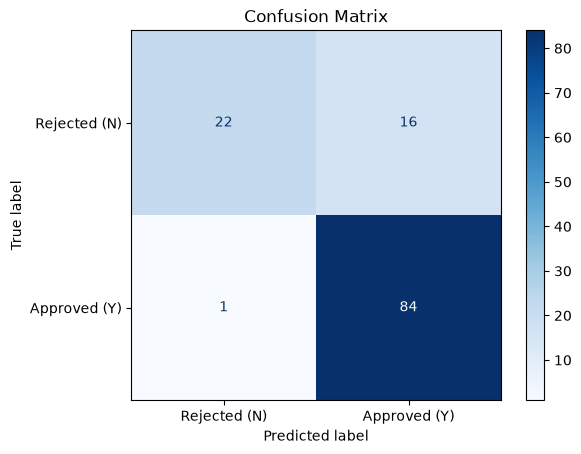

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected (N)", "Approved (Y)"]
)

display_cm.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [24]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Rejected", "Approved"],
    zero_division=0
))

              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



In [25]:
df.to_csv("loan_data_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!



## Conclusion

In this task, we explored the Kaggle Loan Prediction dataset and examined applicant income, loan amount, education, and loan status.

We checked for missing values and duplicate rows and visualized important features using histograms and count plots.

A Logistic Regression model was trained after preparing numerical and categorical features. Its performance was evaluated using accuracy, a confusion matrix, and a classification report.

The model predicts loan approval or rejection based on the available applicant information. The dataset's target represents loan approval status, not actual loan default. Therefore, this model should not be considered an actual loan-default prediction system.
